# Regime map: where single runs are all-or-nothing, where they are graded, and where seed choice matters

Everything so far used calibrated settings where random seed sets succeed about half the time and single runs end all-or-nothing. Seed choice may matter elsewhere too, including settings where the match ratio is spread out (`graded_outcomes.ipynb`, Hernan's sparse percolation runs). This notebook maps percolation, FAQ and GOAT over edge correlation, density and budget before any large data collection.

**Grid.** 600 vertices, mean degree 8, 16 and 32, edge correlation ρ = 0.2, 0.3, 0.4, 0.5, 0.7 and 0.9. ER first, then Chung–Lu (set `MODEL` below), PAPER later. Chung–Lu uses mean degree 10 instead of 8, because at 8 only 12–25% of drawn pairs pass the structure check. All three algorithms run on the same pairs (both graphs connected, no automorphisms).

**Outcome.** Accuracy on 120 fixed test vertices per pair (20%) that are never seeds. It means the same thing at every budget and for every method. Non-seed accuracy and round 1's success flag (accuracy ≥ 0.9 for SGM, ≥ 0.5 for percolation) are recorded too.

| Stage | What it runs | Time with 3 jobs (rough) |
|---|---|---|
| 1. What single runs look like | Random sets only. Budgets 3 to 300 seeds, each about 1.5× the last; 8 sets per budget on 2 pairs per cell, cut to 4 when they all fail or all succeed; climbing stops once two budgets in a row average above 0.95. At the budget closest to 0.5: solver luck (FAQ, GOAT), GOAT with its regulariser halved and doubled, and the spread of 1,000 random sets' features | about 1.5 h for ER |
| 2. Does seed choice matter? | Every cell whose curve rises inside the range: the budgets where random sets average 20%, 50% and 80%, on 4 pairs. 10 random sets, round 1's rules, best of 100 / 1,000 by the frozen score and best of 1,000 by degree | up to 3 h for ER |
| Analysis | Reads saved results only | seconds |

Running from the top runs both stages, so start it in the evening. Reruns resume.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'selection_rule_comparison':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from selection_rule_comparison import regime_map as RM
RM = importlib.reload(RM)   # picks up edits to regime_map.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 250)

MODEL = 'sparse_er'   # then 'chung_lu'; 'paper_pa' later
RUN_STAGE1 = True
RUN_STAGE2 = True
JOBS = 3
print('Results:', RM.OUTPUT_DIR / MODEL)

Results: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/regime_map/sparse_er


## 1. Stage 1: what single runs look like

Random seed sets only, one run each. The cell prints one line per finished pair; the interrupt button stops the workers and rerunning resumes. In a terminal instead, from the repository root: `python -m selection_rule_comparison.regime_map --stage 1 --model sparse_er` (and `--status`).

**Map.** One heatmap per algorithm, with rows for ρ and columns for mean degree.
- **Colour:** the share of single runs ending part-way (test accuracy 0.2–0.8) at the budget closest to 0.5. Light means all-or-nothing; dark means graded.
- **Text:** the budget where random sets average 50%, and the regime label.
- **Grey:** no 50% crossing between 3 and 300 seeds. Such a cell is either easy (above 0.5 already at 3 seeds) or hard (below 0.5 even at 300).

Fri 16:47  Stage 1, ER: 108 pair runs, 3 at a time, about 78 min (a rough guess). One line per finished pair.
Fri 16:51  [1/108] stage 1 GOAT ER, mean degree 8, rho 0.20, pair 0: 94 runs in 3.5 min, middle budget 300; about 77 min left
Fri 16:51  [2/108] stage 1 GOAT ER, mean degree 8, rho 0.30, pair 0: 98 runs in 3.6 min, middle budget 300; about 76 min left
Fri 16:52  [3/108] stage 1 GOAT ER, mean degree 8, rho 0.40, pair 0: 106 runs in 4.7 min, middle budget 90; about 74 min left
Fri 16:52  [4/108] stage 1 GOAT ER, mean degree 8, rho 0.90, pair 0: 24 runs in 0.3 min, middle budget 3; about 73 min left
Fri 16:54  [5/108] stage 1 GOAT ER, mean degree 8, rho 0.70, pair 0: 50 runs in 2.7 min, middle budget 3; about 72 min left
Fri 16:56  [6/108] stage 1 GOAT ER, mean degree 16, rho 0.20, pair 0: 90 runs in 3.8 min, middle budget 300; about 71 min left
Fri 16:57  [7/108] stage 1 GOAT ER, mean degree 8, rho 0.50, pair 0: 102 runs in 5.8 min, middle budget 40; about 70 min left
Fri 16:59  

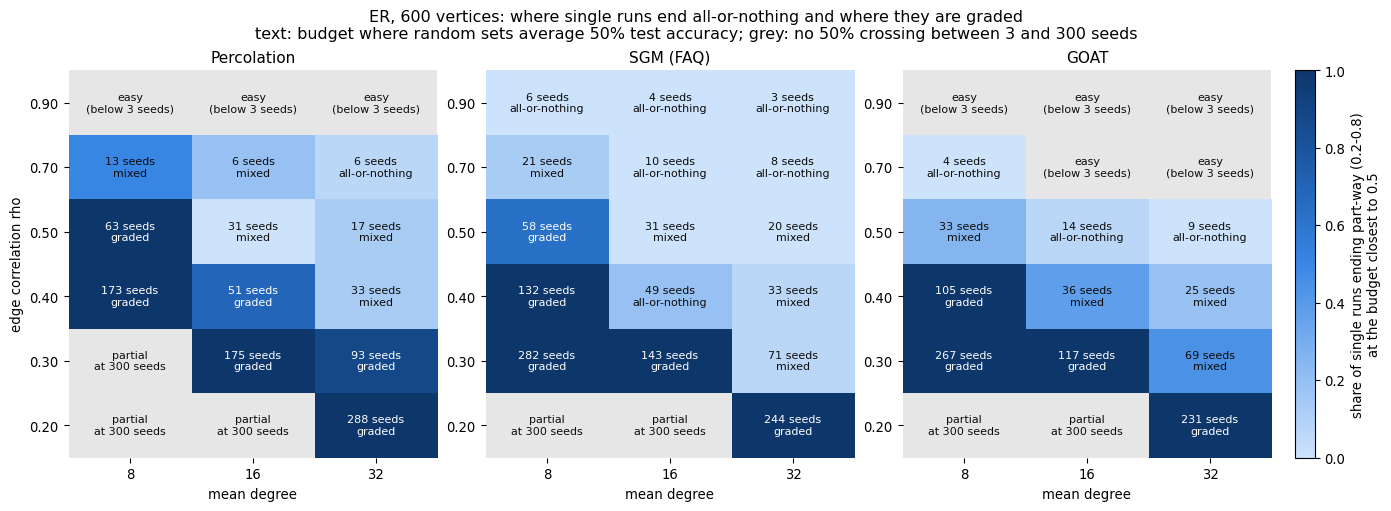

In [2]:
if RUN_STAGE1:
    RM.run_stage1(MODEL, jobs=JOBS)
stage1 = RM.read_stage(MODEL, 1)
regimes = RM.regime_table(stage1, MODEL)
RM.plot_regimes(regimes, MODEL)
plt.show()

### The table

One row per cell; the shares are rough, from 16 runs.
- **regime:**
  - **all-or-nothing:** at least 70% of runs end at or below 0.1 or at or above 0.9;
  - **graded:** at least 60% end between 0.2 and 0.8;
  - **mixed:** in between;
  - **easy, fails throughout, or partial at 300 seeds:** no 50% crossing in range.
- **k20, k50, k80:** budgets where random sets average 20%, 50% and 80% (pairs averaged). **k50 per pair** shows how much the pairs differ.
- **rise (k80/k20):** how fast accuracy rises with budget. Near 1 means a jump; 2 or more means a gradual rise (ER mean degree 16: about 1.4 at ρ = 0.35 and 2.2 at ρ = 0.30).
- **part-way share, all-or-nothing share:** at each pair's budget closest to 0.5. **ceiling:** the highest average accuracy reached.
- **solver share:** the share of the spread between runs at that budget due to the solver seed alone (FAQ, GOAT).
- **GOAT reg x0.5, x2:** the change in mean test accuracy when GOAT's regulariser is halved or doubled on the same sets. Values far from 0 mean the regulariser needs retuning for that cell.
- **feature CV, score SD:** how much random sets differ at that budget (CV of degree and pair mass, and the SD of the frozen score). Small values mean picking the best of N random sets has little room to work (graded_outcomes: CV about 2% at 150 seeds, against 5–12% at round 1's budgets).

In [3]:
for algorithm in RM.ALGORITHMS:
    display(RM.show_regime_table(regimes, algorithm))

pairs                regime    k20    k50    k80 k50 per pair rise (k80/k20) part-way share all-or-nothing share ceiling solver share feature CV score SD runs
algorithm   mean degree rho                                                                                                                                                               
Percolation 8           0.2     2  partial at 300 seeds  298.3                       -, -                         0.688                  0.0   0.202                   0.031    0.667  124
                        0.3     2  partial at 300 seeds  166.5                       -, -                           1.0                  0.0   0.429                   0.032    0.645  140
                        0.4     2                graded   68.3  172.6            166, 178                           1.0                  0.0   0.697                   0.036     0.72  156
                        0.5     2                graded   31.4   62.7  164.0       62, 64            5.2            1.0                  0.0   0.869                   0.076    0.792  164
                        0.7     2                 mixed    9.1   13.3   16.9       14, 13            1.9            0.5                0.188   0.959                   0.273    0.793   96
                        0.9     2  easy (below 3 seeds)                              -, -                           0.0                0.625   0.975                   1.001    0.711   40
            16          0.2     2  partial at 300 seeds  207.0                       -, -                           1.0                  0.0   0.364                   0.021    0.643  128
                        0.3     2                graded   94.8  174.6            166, 185                           1.0                  0.0   0.763                   0.024    0.718  136
                        0.4     2                graded   40.8   51.2   77.1       48, 54            1.9          0.688                0.062   0.969                   0.059    0.784  136
                        0.5     2                 mixed   25.8   31.4   36.8       31, 32            1.4            0.0                0.688   0.996                   0.082    0.788   84
                        0.7     2                 mixed    3.3    5.9    9.7         5, 6            2.9          0.188                0.688   0.992                   0.313    0.761   76
                        0.9     2  easy (below 3 seeds)                              -, -                          0.25                0.562   0.997                   0.534    0.731   44
            32          0.2     2                graded  183.0  288.2            284, 292                           1.0                  0.0    0.53                   0.015    0.639  124
                        0.3     2                graded   66.8   92.7  121.2      101, 83            1.8          0.875                  0.0   0.996                   0.026    0.781  120
                        0.4     2                 mixed   28.6   33.5   39.3       34, 33            1.4          0.125                0.625   0.995                   0.041     0.79   96
                        0.5     2                 mixed   12.6   16.9   22.6       19, 16            1.8          0.125                0.625   0.994                   0.069    0.715   76
                        0.7     2        all-or-nothing    5.0    6.1    7.4         7, 5            1.5          0.062                0.875   0.997                    0.15    0.743   44
                        0.9     2  easy (below 3 seeds)                  4.3         3, -                         0.125                0.875     1.0                   0.274    0.728   44

pairs                regime    k20    k50    k80 k50 per pair rise (k80/k20) part-way share all-or-nothing share ceiling solver share feature CV score SD runs
algorithm mean degree rho                                                                                                                                                               
SGM (FAQ) 8           0.2     2  partial at 300 seeds  275.0                       -, -                          0.75                  0.0   0.223        0.473      0.031    0.415  152
                      0.3     2                graded  150.5  281.6            268, 299                           1.0                  0.0   0.535        0.367      0.032    0.399  160
                      0.4     2                graded   81.8  132.0  292.3     123, 145            3.6            1.0                  0.0   0.806        0.817      0.046    0.516  164
                      0.5     2                graded   43.4   58.4   80.6       56, 61            1.9          0.625                0.125   0.955        0.665      0.076    0.551  172
                      0.7     2                 mixed   18.2   21.3   25.0       22, 21            1.4          0.125                0.312   0.996        0.851      0.191    0.534   96
                      0.9     2        all-or-nothing    5.2    6.1    7.2         6, 6            1.4            0.0                0.938     1.0          1.0      0.581    0.501   68
          16          0.2     2  partial at 300 seeds  194.9                       -, -                           1.0                  0.0   0.426        0.508      0.021    0.386  152
                      0.3     2                graded   92.6  143.3  220.3     141, 145            2.4            1.0                  0.0   0.886        0.409      0.031    0.481  164
                      0.4     2        all-or-nothing   42.0   49.3   57.9       51, 48            1.4          0.188                 0.75   0.984        0.381      0.058    0.561  116
                      0.5     2                 mixed   23.6   30.5   35.9       30, 31            1.5            0.0                0.562     1.0        0.782      0.082    0.558  100
                      0.7     2        all-or-nothing    8.4    9.7   11.2       10, 10            1.3            0.0                0.938     1.0        0.806      0.207    0.516   70
                      0.9     2        all-or-nothing           3.7    4.9         3, 4                           0.0                0.938     1.0        0.744      0.534    0.471   68
          32          0.2     2                graded  151.7  243.7            233, 259                           1.0                  0.0   0.678        0.662      0.015    0.349  148
                      0.3     2                 mixed   62.2   71.4   82.0       72, 71            1.3          0.062                0.375     1.0        0.291      0.033    0.527  124
                      0.4     2                 mixed   28.5   33.0   38.1       34, 32            1.3          0.062                0.688     1.0        0.523      0.047    0.556  100
                      0.5     2                 mixed   15.1   20.0   23.9       20, 20            1.6            0.0                0.625     1.0        0.551      0.069    0.548   84
                      0.7     2        all-or-nothing    6.0    8.1   10.3         7, 9            1.7            0.0                0.875     1.0        0.754      0.124    0.478   72
                      0.9     2        all-or-nothing           3.1    4.1         -, 3                           0.0                  1.0     1.0        0.442      0.274    0.372   52

pairs                regime    k20    k50    k80 k50 per pair rise (k80/k20) part-way share all-or-nothing share ceiling solver share GOAT reg x0.5 GOAT reg x2 feature CV score SD runs
algorithm mean degree rho                                                                                                                                                                                         
GOAT      8           0.2     2  partial at 300 seeds  265.8                       -, -                         0.812                  0.0    0.23          0.0         0.003      -0.001      0.031    0.367  188
                      0.3     2                graded  132.1  266.9            252, 287                           1.0                  0.0    0.55          0.0          0.02      -0.009      0.032    0.351  192
                      0.4     2                graded   54.5  104.8  272.4      95, 115            5.0            1.0                  0.0   0.816          0.0         0.044      -0.024      0.053    0.442  212
                      0.5     2                 mixed   27.3   33.4   43.8       33, 34            1.6           0.25                0.438   0.965          0.0        -0.316      -0.209      0.104    0.441  208
                      0.7     2        all-or-nothing           3.7    5.4         4, 4                           0.0                 0.75   0.996          0.0        -0.206      -0.208      1.028    0.396  108
                      0.9     2  easy (below 3 seeds)                              -, -                           0.0                  1.0     1.0          0.0        -0.065         0.0      1.001    0.396   48
          16          0.2     2  partial at 300 seeds  186.5                       -, -                           1.0                  0.0   0.451          0.0         0.005      -0.011      0.021    0.352  184
                      0.3     2                graded   75.1  117.4  189.7     113, 123            2.5            1.0                  0.0   0.894          0.0         0.096      -0.057      0.031     0.44  200
                      0.4     2                 mixed   28.8   36.3   48.6       33, 43            1.7          0.375                  0.5    0.99          0.0          0.27      -0.123      0.066    0.458  152
                      0.5     2        all-or-nothing   12.3   14.2   16.4       14, 14            1.3          0.062                0.875     1.0          0.0        -0.076      -0.077      0.147    0.429  116
                      0.7     2  easy (below 3 seeds)                              -, -                           0.0                  1.0     1.0          0.0        -0.824      -0.236      0.521    0.416   48
                      0.9     2  easy (below 3 seeds)                              -, -                           0.0                  1.0     1.0          0.0        -0.466         0.0      0.534    0.413   48
          32          0.2     2                graded  140.0  231.1            223, 240                           1.0                  0.0   0.728          0.0         0.031      -0.021      0.017    0.411  184
                      0.3     2                 mixed   53.7   68.6   80.8       71, 66            1.5          0.438                0.062     1.0          0.0         0.277      -0.085      0.033    0.464  152
                      0.4     2                 mixed   19.9   25.0   32.9       27, 24            1.7          0.188                0.562     1.0          0.0         0.249      -0.126      0.053    0.466  136
                      0.5     2        all-or-nothing    7.2    9.3   11.0        9, 10            1.5            0.0                0.875     1.0          0.0        -0.179      -0.068      0.126    0.455  116
                      0.7     2  easy (below 3 seeds)                              -, -                           0.0                  1.0     1.0          0.0        -0.898      -0.119      0.284    0.427   48
                 

### Single runs in every cell

Each dot is one random set's single run. The lines are each pair's mean, and the grey band is 0.2–0.8. In an all-or-nothing cell the dots sit at the top and bottom around the rise; in a graded cell they fill the band.

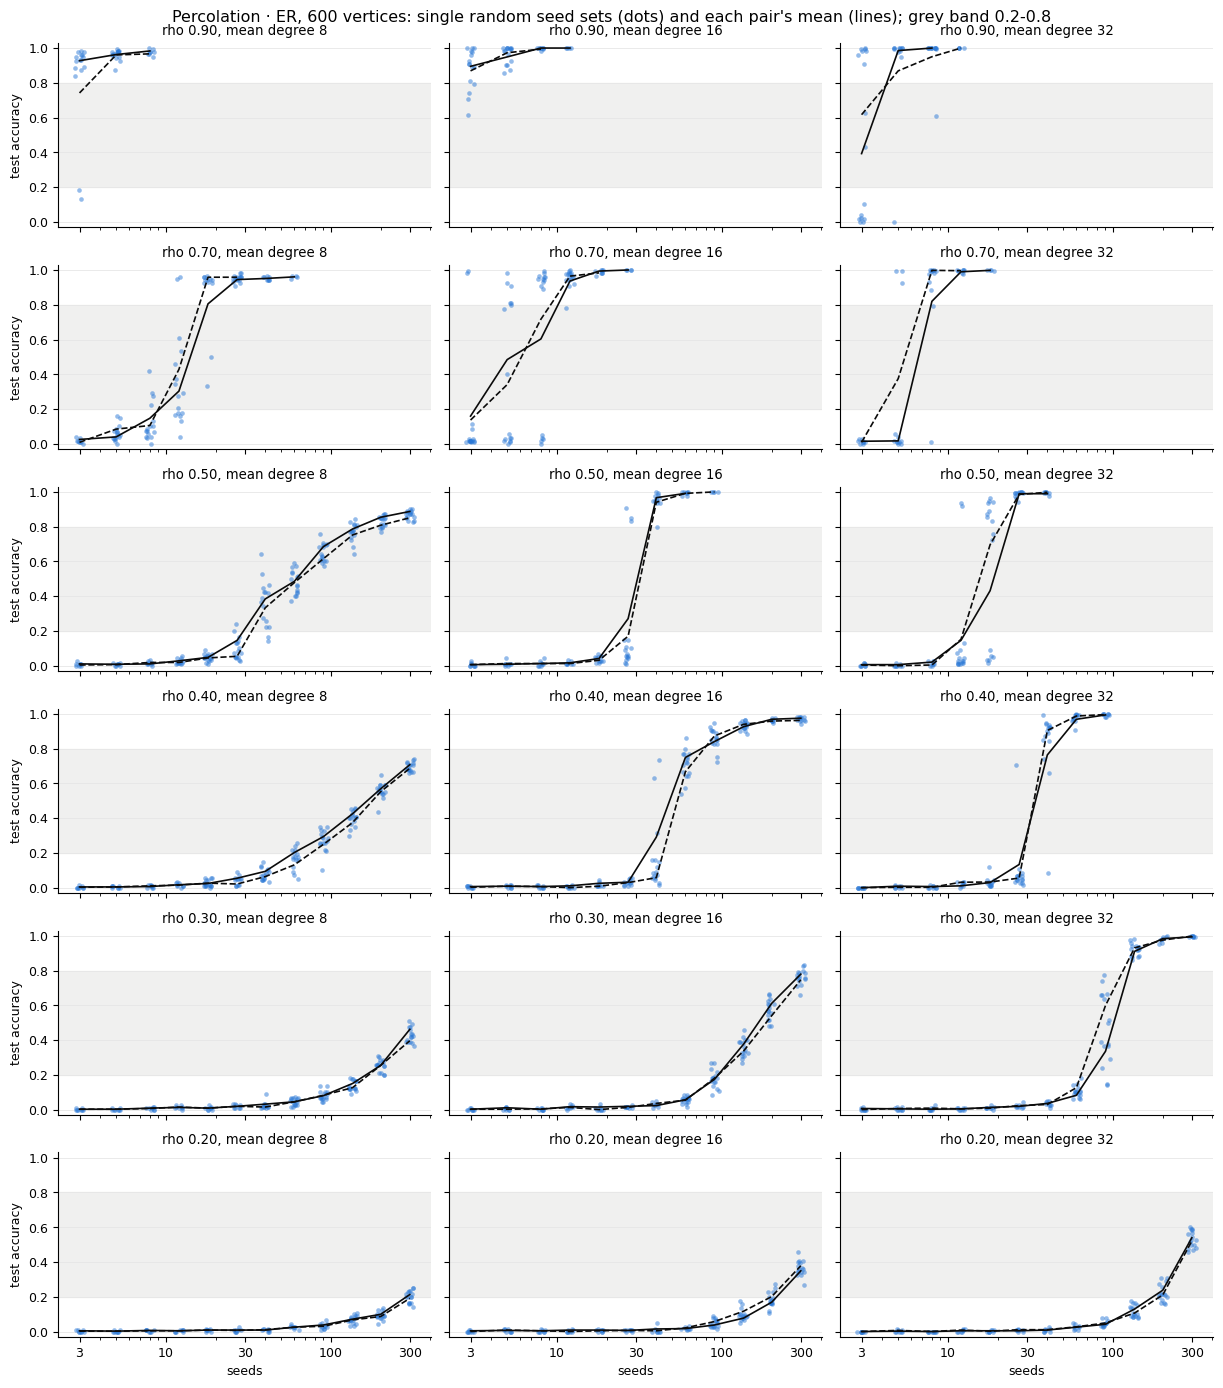

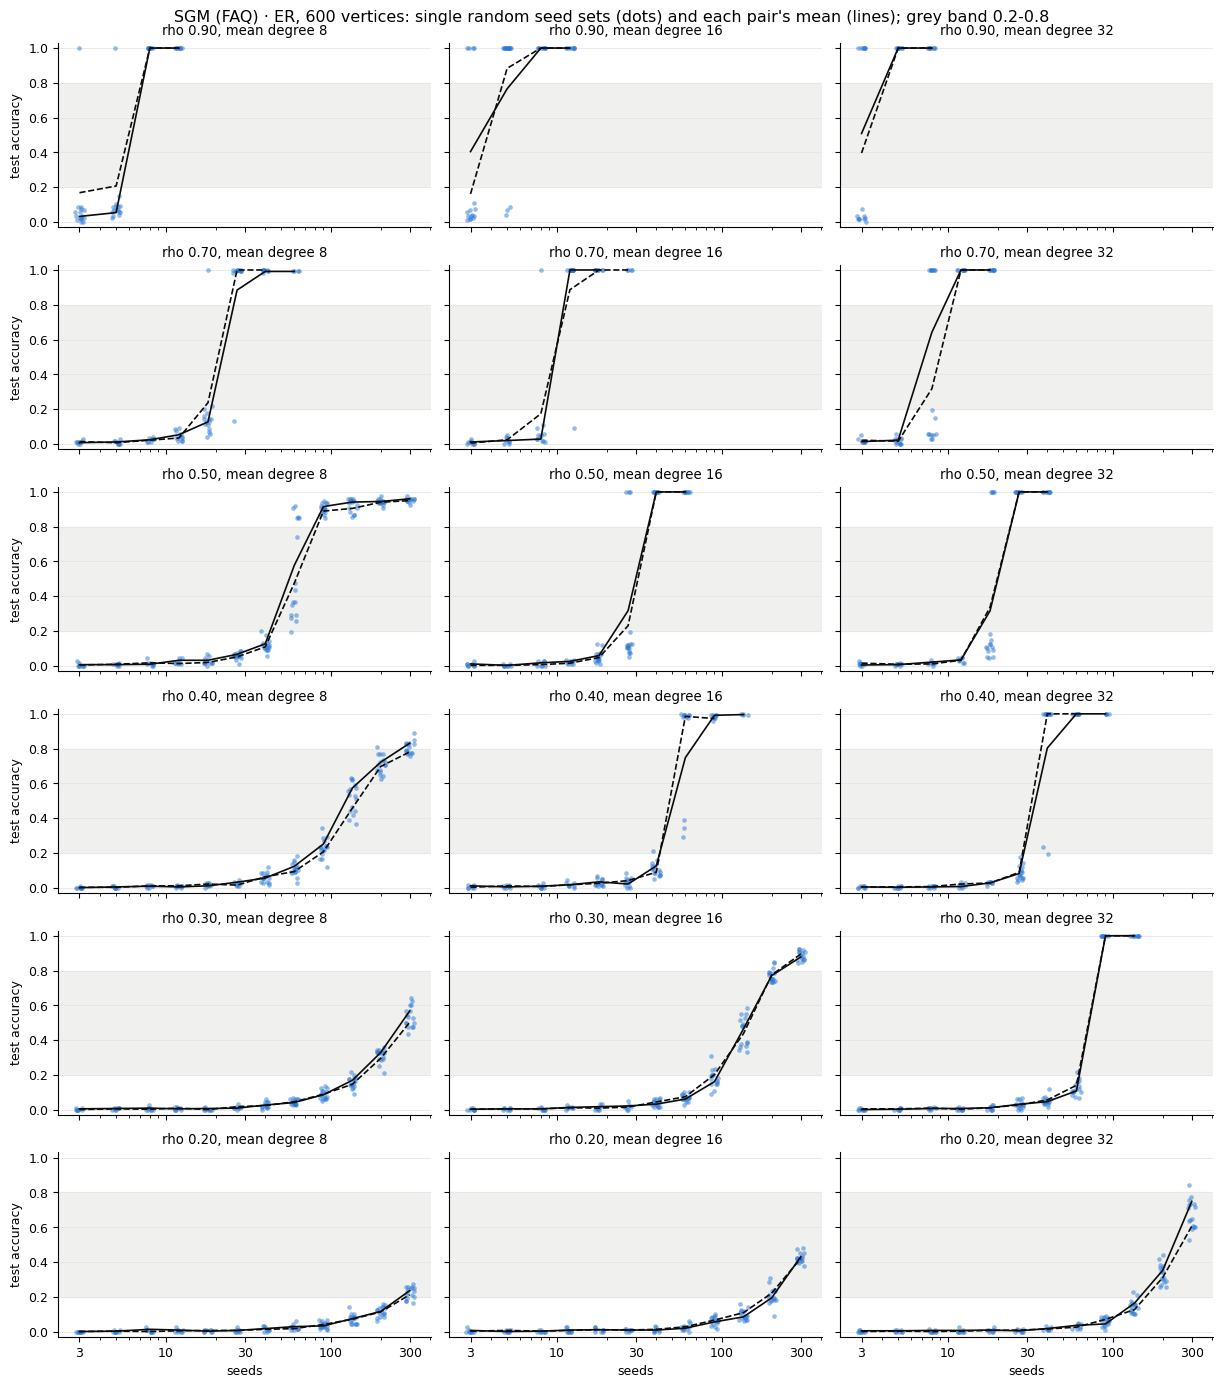

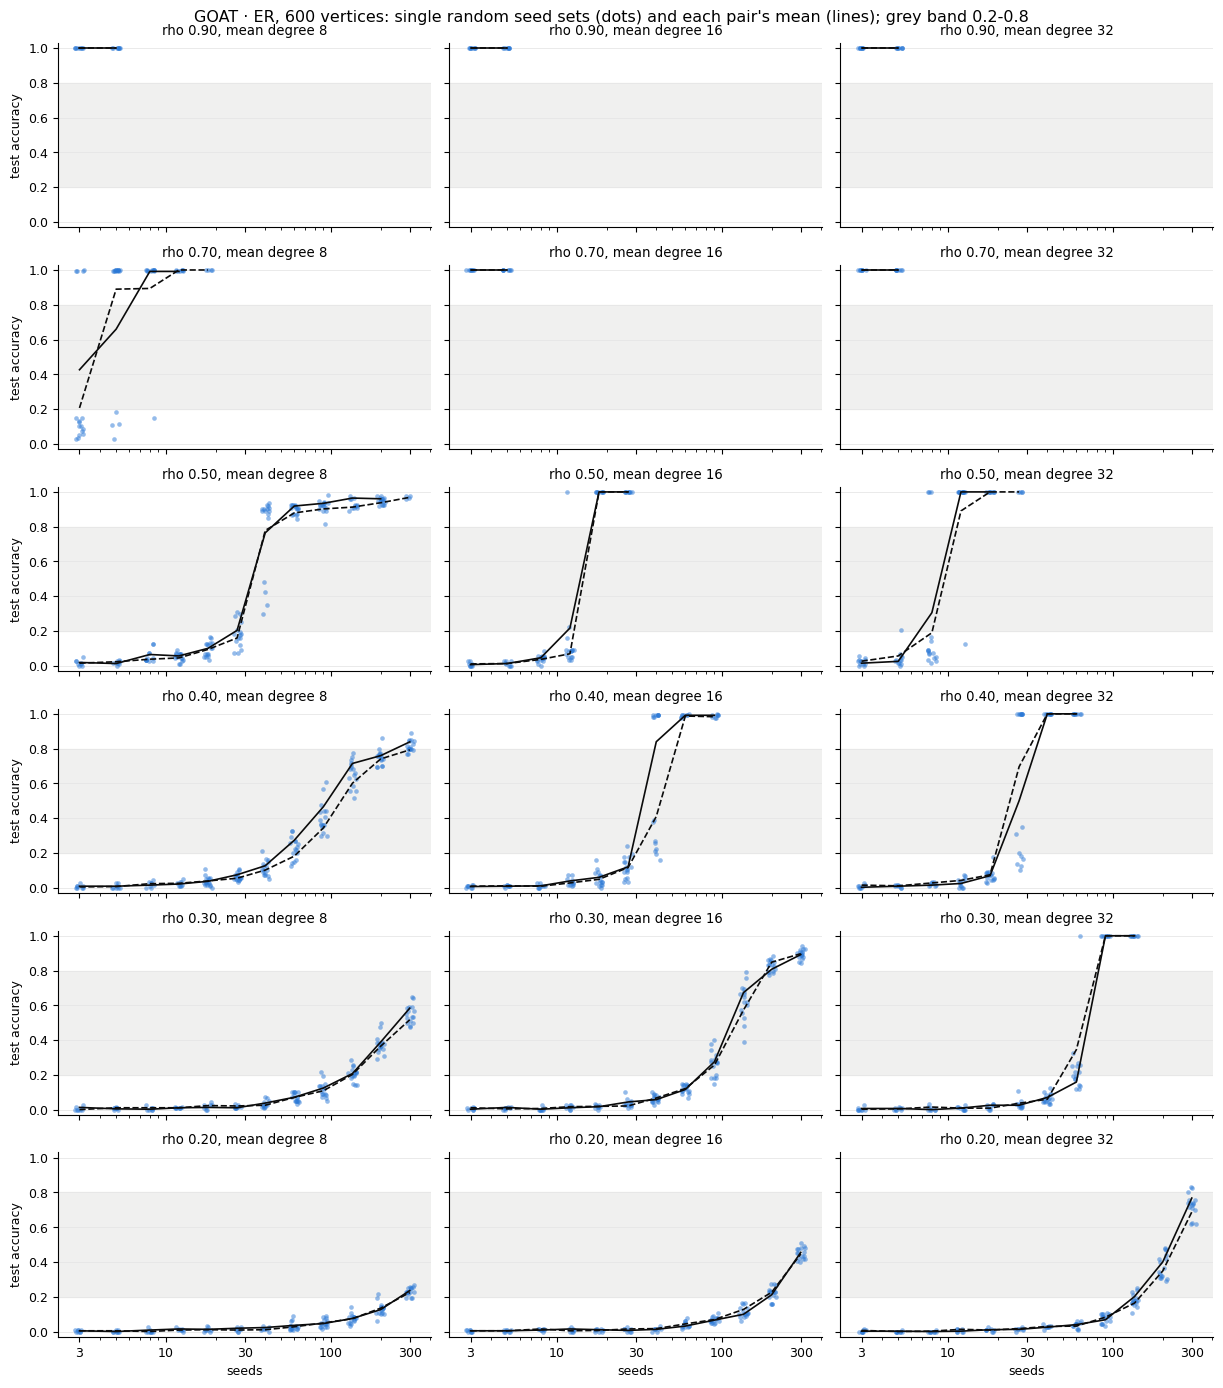

In [4]:
for algorithm in RM.ALGORITHMS:
    RM.plot_curves(stage1, algorithm, MODEL)
    plt.show()

## 2. Stage 2: does seed choice matter?

This runs for every cell whose random-set curve rises across 20–80% inside the budget range, at the budgets where random sets average 20%, 50% and 80%. Those budgets are fixed from stage 1 and saved in `stage2/budgets.json`. Each cell uses 4 pairs: the 2 from stage 1 plus 2 new ones.

Per pair and budget, the methods are:
- **random:** 10 random sets;
- **round 1's rules:** never seeding a test vertex;
- **best of N:** best of 100 and best of 1,000 by the frozen score (the pooled weights for this algorithm and model), and best of 1,000 by degree.

FAQ runs each rule or best-of set 3 times and averages; GOAT and percolation run once. In a terminal: `python -m selection_rule_comparison.regime_map --stage 2 --model sparse_er`.

In [5]:
if RUN_STAGE2:
    RM.run_stage2(MODEL, jobs=JOBS)
display(RM.status(MODEL))

No 20-80% rise inside the budget range, so no stage 2, for 15 cells: Percolation d8 rho 0.20, SGM (FAQ) d8 rho 0.20, GOAT d8 rho 0.20, Percolation d8 rho 0.30, Percolation d8 rho 0.90, GOAT d8 rho 0.90, Percolation d16 rho 0.20, SGM (FAQ) d16 rho 0.20, GOAT d16 rho 0.20, GOAT d16 rho 0.70, Percolation d16 rho 0.90, GOAT d16 rho 0.90, GOAT d32 rho 0.70, Percolation d32 rho 0.90, GOAT d32 rho 0.90
Fri 17:51  Stage 2, ER: 156 pair runs, 3 at a time, about 124 min (a rough guess). One line per finished pair.
Fri 17:53  [1/156] stage 2 SGM (FAQ) ER, mean degree 8, rho 0.40, pair 2: 93 runs in 1.5 min; about 121 min left
Fri 17:53  [2/156] stage 2 SGM (FAQ) ER, mean degree 8, rho 0.40, pair 0: 93 runs in 1.5 min; about 121 min left
Fri 17:53  [3/156] stage 2 SGM (FAQ) ER, mean degree 8, rho 0.40, pair 1: 93 runs in 1.5 min; about 120 min left
Fri 17:54  [4/156] stage 2 SGM (FAQ) ER, mean degree 8, rho 0.40, pair 3: 93 runs in 1.6 min; about 118 min left
Fri 17:56  [5/156] stage 2 SGM (FAQ) E

,,,stage 1 pairs,stage 2 budgets,stage 2 pairs
algorithm,mean degree,rho,,,
Percolation,8,0.2,2 of 2,none,-
SGM (FAQ),8,0.2,2 of 2,none,-
GOAT,8,0.2,2 of 2,none,-
Percolation,8,0.3,2 of 2,none,-
SGM (FAQ),8,0.3,2 of 2,"151, 282",4 of 4
GOAT,8,0.3,2 of 2,"132, 267",4 of 4
Percolation,8,0.4,2 of 2,"68, 173",4 of 4
SGM (FAQ),8,0.4,2 of 2,"82, 132, 292",4 of 4
GOAT,8,0.4,2 of 2,"54, 105, 272",4 of 4


### Where seed choice matters

**Top row:** the best of round 1's rules in each cell, as its gain in test accuracy over random sets on the same pairs and budgets, averaged over the stage 2 budgets. The text names the rule.

**Bottom row:** best of 1,000 random sets by the frozen score.

Blue is better than random, red is worse, and grey means the cell had no stage 2. The table gives each cell's best rule with a 95% interval over pairs, and its gain in seeds saved. Its last columns describe random sets' single runs at the 50% budget, from 40 runs, so they are firmer than stage 1's 16.

**Seeds saved** is how many more seeds random sets would need for the same accuracy, as a share of the budget (0.3 means random sets need 30% more seeds). It is read off each pair's random-set curve: budgets 3 to 300 on the 2 stage 1 pairs, and only the 3 stage 2 budgets on the 2 new pairs. When a method beats random sets at every budget on the curve, the largest budget is used, so the number is then a lower bound.

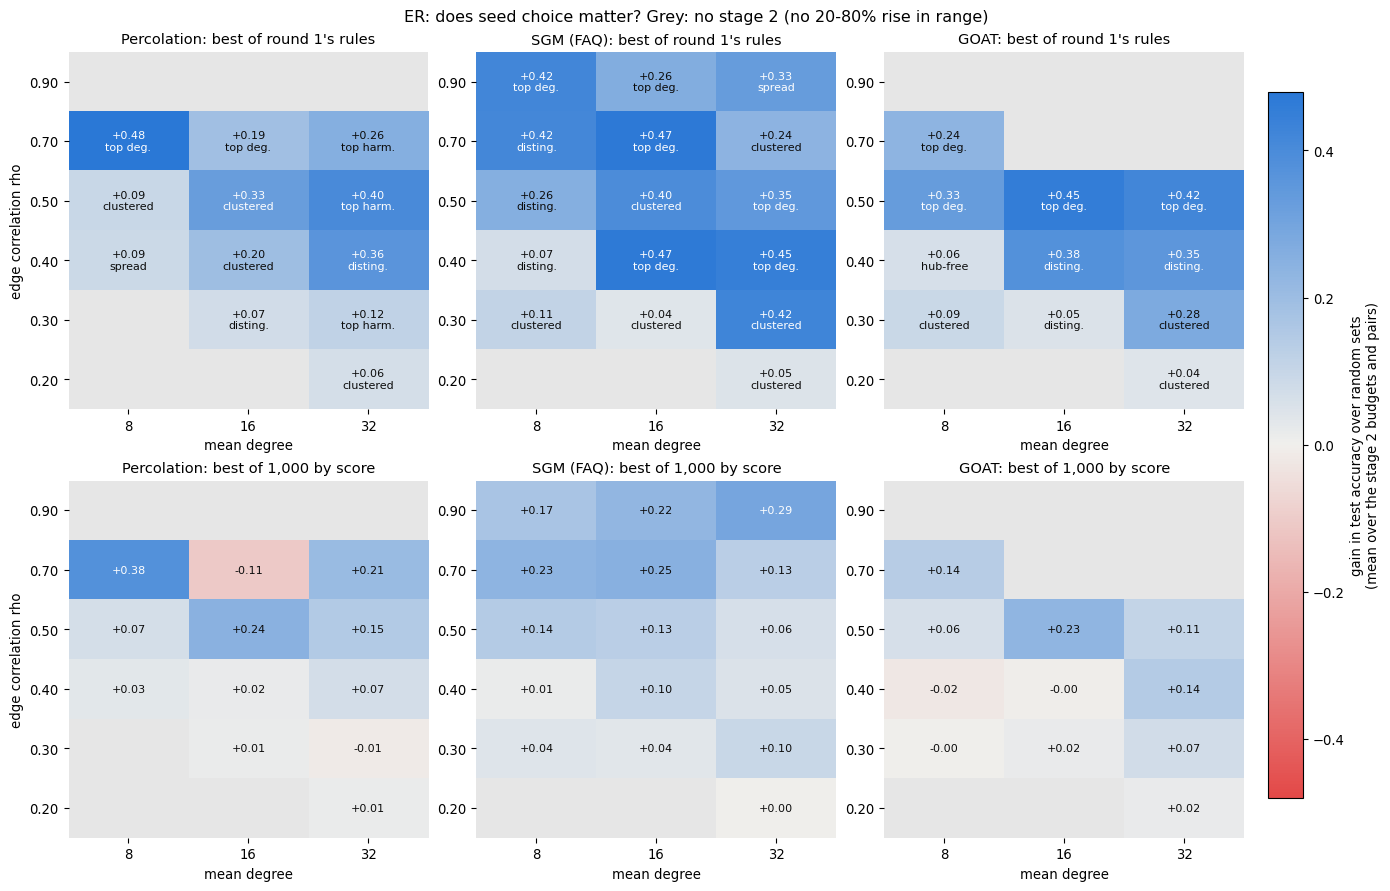

,,,best rule,best rule gain,best rule interval,best rule seeds saved,top degree gain,"best of 1,000 by score gain","best of 1,000 by degree gain",random runs at 50%,part-way share,all-or-nothing share
algorithm,mean degree,rho,,,,,,,,,,
SGM (FAQ),8,0.3,clustered,0.110,+0.040 to +0.180,0.141,0.044,0.042,0.046,40,1.000,0.000
GOAT,8,0.3,clustered,0.093,+0.049 to +0.136,0.159,0.048,-0.002,0.027,40,1.000,0.000
SGM (FAQ),8,0.4,distinguishing,0.069,+0.041 to +0.097,0.179,0.023,0.015,0.019,40,1.000,0.000
GOAT,8,0.4,hub_free_distinguishing,0.063,+0.024 to +0.103,0.191,0.046,-0.021,-0.003,40,1.000,0.000
Percolation,8,0.4,spread,0.089,+0.027 to +0.151,0.304,0.055,0.031,0.023,40,1.000,0.000
SGM (FAQ),8,0.5,distinguishing,0.257,+0.177 to +0.337,0.304,0.191,0.142,0.097,40,0.875,0.025
GOAT,8,0.5,top_degree,0.331,+0.256 to +0.407,0.331,0.331,0.062,0.125,40,0.650,0.125
Percolation,8,0.5,clustered,0.094,+0.033 to +0.155,0.131,0.071,0.066,0.061,40,1.000,0.000
SGM (FAQ),8,0.7,distinguishing,0.415,+0.325 to +0.505,0.289,0.414,0.233,0.189,40,0.225,0.450


In [6]:
stage2 = RM.read_stage(MODEL, 2)
gains = RM.gain_table(stage2, stage1)
RM.plot_gains(gains, MODEL, regimes)
plt.show()
best = RM.best_table(gains, stage2)
display(best.assign(algorithm=best['algorithm'].map(RM.LABELS)).drop(columns='model')
        .set_index(['algorithm', 'mean degree', 'rho']).round(3))

### Every method

The gain over random sets at each stage 2 budget and on average, with 95% intervals over pairs (4 pairs, so wide), and seeds saved (median over pairs and budgets).

In [7]:
for algorithm in RM.ALGORITHMS:
    display(RM.show_gain_table(gains, algorithm))

pairs   gain gain at 20% gain at 50% seeds saved gain at 80%      95% interval
algorithm   mean degree rho method                                                                                                
Percolation 8           0.4 top degree                  4  0.055       0.066       0.043       0.172              +0.014 to +0.096
                            top harmonic                4  0.051       0.085       0.016       0.192              -0.001 to +0.102
                            clustered (pair mass)       4  0.049       0.073       0.026       0.141              +0.003 to +0.096
                            spread (coverage)           4  0.089        0.15       0.028       0.304              +0.027 to +0.151
                            distinguishing              4   0.08       0.071       0.089       0.235              +0.056 to +0.103
                            best of 100 by score        4 -0.008       0.025       -0.04         0.0              -0.097 to +0.081
                            best of 1,000 by score      4  0.031       0.054       0.007       0.015              -0.017 to +0.079
                            best of 1,000 by degree     4  0.023       0.046       0.001       0.011              -0.038 to +0.085
                        0.5 top degree                  4  0.071       0.178        0.05       0.157      -0.014  +0.068 to +0.074
                            top harmonic                4  0.031       0.113      -0.009        0.02      -0.012  -0.045 to +0.107
                            clustered (pair mass)       4  0.094       0.199       0.069       0.131       0.015  +0.033 to +0.155
                            spread (coverage)           4  0.031       0.107      -0.011       0.025      -0.003  -0.040 to +0.102
                            distinguishing              4  0.081       0.196       0.044       0.168       0.003  +0.001 to +0.161
                            best of 100 by score        4   0.05       0.165      -0.044       0.133       0.028  -0.034 to +0.134
                            best of 1,000 by score      4  0.066       0.151       0.044        0.13       0.003  +0.003 to +0.129
                            best of 1,000 by degree     4  0.061       0.119       0.052        0.13       0.011  +0.022 to +0.100
                        0.7 top degree                  4  0.479       0.728       0.539       0.889       0.171  +0.325 to +0.634
                            top harmonic                4  0.423       0.568        0.52       0.473       0.182  +0.267 to +0.579
                            clustered (pair mass)       4  0.382       0.565       0.403       0.338       0.178  -0.037 to +0.801
                            spread (coverage)           4  0.237       0.176        0.37       0.123       0.165  -0.146 to +0.620
                            distinguishing              4  0.472       0.742       0.516       0.419       0.157  +0.332 to +0.612
                            best of 100 by score        4  0.266       0.261       0.366       0.266       0.171  -0.104 to +0.636
                            best of 1,000 by score      4  0.376       0.563       0.378       0.478       0.186  +0.111 to +0.640
                            best of 1,000 by degree     4  0.192       0.178       0.214       0.068       0.186  -0.028 to +0.413
            16          0.3 top degree                  4  0.052       0.085       0.019       0.102              +0.026 to +0.077
                            top harmonic                4  0.004       0.012      -0.004         0.0              -0.025 to +0.033
                            clustered (pair mass)       4   0.06       0.048       0.073        0.09              +0.015 to +0.105
                            spread (coverage)           4   0.03       0.025       0.035       0.027              -0.014 to +0.074
                            distinguishing              4  0.073       0.104       0.041       0.104              +0.043 t

pairs   gain gain at 20% gain at 50% seeds saved gain at 80%      95% interval
algorithm mean degree rho method                                                                                                
SGM (FAQ) 8           0.3 top degree                  4  0.044       0.069       0.019       0.033              -0.034 to +0.122
                          clustered (pair mass)       4   0.11       0.134       0.086       0.141              +0.040 to +0.180
                          spread (coverage)           4   0.06       0.081       0.039       0.044              -0.034 to +0.153
                          distinguishing              4  0.071       0.095       0.046       0.089              +0.021 to +0.120
                          best of 100 by score        4  0.029       0.053       0.005       0.063              +0.003 to +0.055
                          best of 1,000 by score      4  0.042       0.047       0.037       0.064              +0.015 to +0.068
                          best of 1,000 by degree     4  0.046       0.043        0.05       0.045              +0.029 to +0.064
                      0.4 top degree                  4  0.023       0.077       0.017       0.004      -0.025  -0.011 to +0.057
                          clustered (pair mass)       4  0.067       0.122       0.093       0.204      -0.015  +0.050 to +0.083
                          spread (coverage)           4   0.06       0.152       0.072       0.152      -0.043  +0.010 to +0.110
                          distinguishing              4  0.069       0.136       0.102       0.179      -0.032  +0.041 to +0.097
                          best of 100 by score        4  0.009       0.012       0.018         0.0      -0.002  -0.064 to +0.083
                          best of 1,000 by score      4  0.015       0.031        0.02       0.013      -0.007  -0.023 to +0.052
                          best of 1,000 by degree     4  0.019       0.018       0.037       0.012       0.003  -0.030 to +0.069
                      0.5 top degree                  4  0.191       0.197       0.408       0.251      -0.033  +0.127 to +0.255
                          clustered (pair mass)       4  0.228        0.29        0.43       0.295      -0.037  +0.180 to +0.276
                          spread (coverage)           4   0.23       0.205       0.506       0.139      -0.022  +0.110 to +0.349
                          distinguishing              4  0.257       0.286       0.499       0.304      -0.013  +0.177 to +0.337
                          best of 100 by score        4  0.031       0.016       0.071         0.0       0.006  -0.062 to +0.124
                          best of 1,000 by score      4  0.142       0.093        0.34       0.102      -0.006  +0.060 to +0.224
                          best of 1,000 by degree     4  0.097       0.046       0.258       0.057      -0.013  -0.032 to +0.226
                      0.7 top degree                  4  0.414        0.71       0.494       0.288       0.038  +0.326 to +0.502
                          clustered (pair mass)       4  0.414       0.711       0.493       0.289       0.038  +0.327 to +0.500
                          spread (coverage)           4  0.391        0.64       0.494       0.254       0.039  +0.341 to +0.441
                          distinguishing              4  0.415       0.711       0.495       0.289        0.04  +0.325 to +0.505
                          best of 100 by score        4  0.252       0.293       0.423        0.16       0.039  +0.000 to +0.503
                          best of 1,000 by score      4  0.233       0.365       0.295       0.104        0.04  -0.041 to +0.508
                          best of 1,000 by degree     4  0.189       0.172       0.357       0.134       0.039  +0.023 to +0.356
                      0.9 top degree                  4  0.417       0.524       0.433        0.25       0.292  +0.191 to +0.642
                          clustered (pair mass)    

pairs   gain gain at 20% gain at 50% seeds saved gain at 80%      95% interval
algorithm mean degree rho method                                                                                                
GOAT      8           0.3 top degree                  4  0.048       0.077       0.019       0.045              +0.016 to +0.081
                          clustered (pair mass)       4  0.093        0.11       0.075       0.159              +0.049 to +0.136
                          spread (coverage)           4  0.052       0.075        0.03       0.015              -0.025 to +0.130
                          distinguishing              4  0.057       0.079       0.036       0.034              +0.009 to +0.106
                          hub-free distinguishing     4  0.073       0.102       0.044       0.124              +0.035 to +0.111
                          best of 100 by score        4 -0.002       0.006       -0.01      -0.012              -0.047 to +0.043
                          best of 1,000 by score      4 -0.002       0.008      -0.012      -0.017              -0.013 to +0.009
                          best of 1,000 by degree     4  0.027       0.027       0.028       0.026              +0.008 to +0.047
                      0.4 top degree                  4  0.046        0.12       0.046       0.113      -0.028  +0.005 to +0.087
                          clustered (pair mass)       4  0.041       0.066       0.067       0.095       -0.01  +0.006 to +0.077
                          spread (coverage)           4  0.063       0.135       0.092       0.209      -0.039  +0.045 to +0.081
                          distinguishing              4   0.05       0.106       0.061       0.127      -0.016  +0.040 to +0.060
                          hub-free distinguishing     4  0.063       0.125       0.092       0.191      -0.026  +0.024 to +0.103
                          best of 100 by score        4 -0.014      -0.023      -0.018      -0.007       0.001  -0.044 to +0.017
                          best of 1,000 by score      4 -0.021        -0.0      -0.054      -0.021       -0.01  -0.048 to +0.006
                          best of 1,000 by degree     4 -0.003       0.023      -0.043         0.0       0.011  -0.050 to +0.043
                      0.5 top degree                  4  0.331       0.504       0.466       0.331       0.024  +0.256 to +0.407
                          clustered (pair mass)       4  0.293       0.477       0.393       0.324       0.009  +0.147 to +0.439
                          spread (coverage)           4  0.309       0.469       0.464        0.32      -0.005  +0.141 to +0.477
                          distinguishing              4  0.272       0.342       0.466       0.277       0.009  +0.171 to +0.373
                          hub-free distinguishing     4  0.325       0.496       0.468       0.333       0.011  +0.226 to +0.423
                          best of 100 by score        4  0.179       0.188       0.322       0.193       0.028  -0.002 to +0.360
                          best of 1,000 by score      4  0.062       0.015       0.157       0.023       0.013  -0.055 to +0.178
                          best of 1,000 by degree     4  0.125       0.058       0.311       0.013       0.005  +0.025 to +0.224
                      0.7 top degree                  4  0.235                    0.36       0.425       0.111  +0.095 to +0.376
                          clustered (pair mass)       4  0.235                    0.36       0.425       0.111  +0.095 to +0.376
                          spread (coverage)           4  0.127                   0.143       0.425       0.111  -0.262 to +0.516
                          distinguishing              4  0.235                    0.36       0.425       0.111  +0.095 to +0.376
                          hub-free distinguishing     4  0.235                    0.36       0.425       0.111  +0.095 to +0.376
                          best of 100 by score     

## Next

- **Chung–Lu:** set `MODEL = 'chung_lu'` in the setup cell and run the notebook from the top again. Results go to their own folder. PAPER comes later.
- **Where to collect more data,** for example a regression model for graded cells: only in cells where seed choice matters (the best rule saves at least about 15% of seeds, or best of 1,000 gains at least 3 points) and where random sets still differ (feature CV not tiny). Such data should include constructed sets as well as random ones.